<div style="background:#0b3d5c;color:white;padding:18px 22px;border-radius:8px">
<h1 style="color:white;margin:0">CS4085 Deep Learning — Lab 4: Regularization</h1>
<p style="margin:6px 0 0 0">L2 regularization and Dropout, implemented from scratch in NumPy</p>
<p style="margin:6px 0 0 0"><b>Instructor:</b> Dr. Naila Marir &nbsp;|&nbsp; College of Engineering, Effat University</p>
</div>

**Student name:** Najeyah Waseem &nbsp;&nbsp; **Student ID:** S23108393 &nbsp;&nbsp; **Date:** 20 Oct 2026

## Lab at a glance

| | |
|---|---|
| **Topic** | Overfitting and two ways to fight it: **L2 regularization** and **Dropout** |
| **Builds on** | Lab 3 (weight initialization) and your forward/backward propagation code |
| **Tools** | Python, NumPy, Matplotlib only. Everything you need is inside this notebook, plus two data files (`lab4_train.csv`, `lab4_test.csv`) from Blackboard. |
| **Estimated time** | About 2 hours |
| **What you hand in** | This notebook, fully run, with all exercises and questions answered |

### Learning outcomes
By the end of this lab you will be able to:
1. **Recognise overfitting** by comparing training and test accuracy, and by looking at a decision boundary.
2. **Implement L2 regularization**: add a penalty to the cost and the matching term to the gradients.
3. **Implement inverted dropout** in both the forward and the backward pass.
4. **Compare** the three models and explain *why* regularization can lower training accuracy but raise test accuracy.

### How to work through this lab
1. Download the two data files from Blackboard (see Part 1).
2. Run every cell **from top to bottom**, in order (`Kernel → Restart & Run All` is the safest way to check).
3. Write code **only** between `# YOUR CODE STARTS HERE` and `# YOUR CODE ENDS HERE`. Replace each `None`.
4. After every exercise, run the **test cell** underneath it. You should see ✅ for every check.
5. Answer the **✍️ Questions** in the markdown cells provided.

## Contents
- [Part 0 — Setup](#p0)
- [Part 1 — The problem and the data](#p1)
- [Part 2 — What is overfitting?](#p2)
- [Part 3 — Baseline model (no regularization)](#p3)
- [Part 4 — L2 regularization](#p4)
    - Exercise 1 — `compute_cost_with_regularization`
    - Exercise 2 — `backward_propagation_with_regularization`
- [Part 5 — Dropout](#p5)
    - Exercise 3 — `forward_propagation_with_dropout`
    - Exercise 4 — `backward_propagation_with_dropout`
- [Part 6 — Experiment: choosing λ](#p6)
- [Part 7 — Results and conclusions](#p7)

<a name="p0"></a>
## Part 0 — Setup
Run the three cells below. The first imports the libraries, the second loads helper functions that are already written for you (activations, the baseline forward/backward pass, plotting, and the dataset), and the third loads the automatic tests.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams["figure.figsize"] = (7.0, 4.0)
np.set_printoptions(precision=6, suppress=True)

In [2]:
# ============================================================
#  HELPER FUNCTIONS — provided for you. Run this cell, do not edit it.
# ============================================================

def sigmoid(x):
    """Sigmoid activation: squashes any number into (0, 1)."""
    return 1 / (1 + np.exp(-x))

def relu(x):
    """ReLU activation: keeps positive values, sets negative values to 0."""
    return np.maximum(0, x)

def initialize_parameters(layer_dims):
    """Scaled random initialization (you met this idea in Lab 3).
    layer_dims -- list, e.g. [2, 20, 3, 1]
    Returns a dictionary with W1, b1, ..., WL, bL."""
    np.random.seed(3)
    parameters = {}
    for l in range(1, len(layer_dims)):
        parameters["W" + str(l)] = np.random.randn(layer_dims[l], layer_dims[l - 1]) / np.sqrt(layer_dims[l - 1])
        parameters["b" + str(l)] = np.zeros((layer_dims[l], 1))
    return parameters

def forward_propagation(X, parameters):
    """LINEAR -> RELU -> LINEAR -> RELU -> LINEAR -> SIGMOID (no regularization)."""
    W1, b1 = parameters["W1"], parameters["b1"]
    W2, b2 = parameters["W2"], parameters["b2"]
    W3, b3 = parameters["W3"], parameters["b3"]
    Z1 = np.dot(W1, X) + b1;  A1 = relu(Z1)
    Z2 = np.dot(W2, A1) + b2; A2 = relu(Z2)
    Z3 = np.dot(W3, A2) + b3; A3 = sigmoid(Z3)
    cache = (Z1, A1, W1, b1, Z2, A2, W2, b2, Z3, A3, W3, b3)
    return A3, cache

def backward_propagation(X, Y, cache):
    """Backward pass of the baseline model (no regularization)."""
    m = X.shape[1]
    (Z1, A1, W1, b1, Z2, A2, W2, b2, Z3, A3, W3, b3) = cache
    dZ3 = A3 - Y
    dW3 = 1. / m * np.dot(dZ3, A2.T)
    db3 = 1. / m * np.sum(dZ3, axis=1, keepdims=True)
    dA2 = np.dot(W3.T, dZ3)
    dZ2 = np.multiply(dA2, np.int64(A2 > 0))
    dW2 = 1. / m * np.dot(dZ2, A1.T)
    db2 = 1. / m * np.sum(dZ2, axis=1, keepdims=True)
    dA1 = np.dot(W2.T, dZ2)
    dZ1 = np.multiply(dA1, np.int64(A1 > 0))
    dW1 = 1. / m * np.dot(dZ1, X.T)
    db1 = 1. / m * np.sum(dZ1, axis=1, keepdims=True)
    return {"dZ3": dZ3, "dW3": dW3, "db3": db3, "dA2": dA2, "dZ2": dZ2, "dW2": dW2,
            "db2": db2, "dA1": dA1, "dZ1": dZ1, "dW1": dW1, "db1": db1}

def compute_cost(A3, Y):
    """Cross-entropy cost (equation 1 in the lab)."""
    m = Y.shape[1]
    A3 = np.clip(A3, 1e-12, 1 - 1e-12)          # avoids log(0) warnings
    logprobs = np.multiply(-np.log(A3), Y) + np.multiply(-np.log(1 - A3), 1 - Y)
    return 1. / m * np.nansum(logprobs)

def update_parameters(parameters, grads, learning_rate):
    """One step of gradient descent: W = W - learning_rate * dW (same for b)."""
    L = len(parameters) // 2
    for l in range(1, L + 1):
        parameters["W" + str(l)] = parameters["W" + str(l)] - learning_rate * grads["dW" + str(l)]
        parameters["b" + str(l)] = parameters["b" + str(l)] - learning_rate * grads["db" + str(l)]
    return parameters

def predict(X, Y, parameters):
    """Predicts labels (0/1) WITHOUT dropout, prints and returns the accuracy."""
    A3, _ = forward_propagation(X, parameters)
    predictions = (A3 > 0.5).astype(int)
    accuracy = np.mean(predictions == Y)
    print("   Accuracy: {:.1f}%".format(100 * accuracy))
    return accuracy

def predict_dec(parameters, X):
    """Used only for plotting the decision boundary."""
    A3, _ = forward_propagation(X, parameters)
    return (A3 > 0.5)

def plot_decision_boundary(model_fn, X, Y, title=""):
    """Colours the field by the model's prediction and overlays the training points."""
    x_min, x_max, y_min, y_max = -0.75, 0.40, -0.75, 0.65
    h = 0.005
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    Z = model_fn(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.contourf(xx, yy, Z, cmap=plt.cm.RdBu, alpha=0.35)
    plt.scatter(X[0, :], X[1, :], c=Y.ravel(), s=25, cmap=plt.cm.RdBu, edgecolors="k", linewidths=0.4)
    plt.xlim(x_min, x_max); plt.ylim(y_min, y_max)
    plt.xlabel("x1 (field length)"); plt.ylabel("x2 (field width)")
    plt.title(title); plt.show()

def load_2D_dataset(train_file="lab4_train.csv", test_file="lab4_test.csv", plot=True):
    """Reads the football dataset from the two CSV files (columns: x1, x2, label).
    Returns train_X (2, m_train), train_Y (1, m_train), test_X (2, m_test), test_Y (1, m_test)."""
    import os
    for f in (train_file, test_file):
        if not os.path.exists(f):
            raise FileNotFoundError(
                "Cannot find '{}'. Download lab4_train.csv and lab4_test.csv from Blackboard and "
                "upload them (Colab) or put them in the same folder as this notebook ({}).".format(f, os.getcwd()))
    train = np.loadtxt(train_file, delimiter=",", skiprows=1)
    test = np.loadtxt(test_file, delimiter=",", skiprows=1)
    # each row in the file is ONE example -> transpose so each COLUMN is one example
    train_X, train_Y = train[:, :2].T, train[:, 2].astype(int).reshape(1, -1)
    test_X, test_Y = test[:, :2].T, test[:, 2].astype(int).reshape(1, -1)
    if plot:
        plt.scatter(train_X[0, :], train_X[1, :], c=train_Y.ravel(), s=25, cmap=plt.cm.RdBu,
                    edgecolors="k", linewidths=0.4)
        plt.xlabel("x1 (field length)"); plt.ylabel("x2 (field width)")
        plt.title("Training set: blue = our player wins the header, red = opponent wins")
        plt.show()
    return train_X, train_Y, test_X, test_Y

def draw_dropout_example(keep_prob=0.5, layer_sizes=(2, 6, 6, 1), n_iterations=2, seed=0):
    """Draws the same network in several training iterations, each with a different dropout mask."""
    rng = np.random.RandomState(seed)
    fig, axes = plt.subplots(1, n_iterations, figsize=(5 * n_iterations, 3.6))
    for it, ax in enumerate(np.atleast_1d(axes)):
        pos, alive = [], []
        for l, n in enumerate(layer_sizes):
            ys = np.linspace(0, 1, n + 2)[1:-1]
            pos.append([(l, y) for y in ys])
            hidden = 0 < l < len(layer_sizes) - 1
            alive.append(rng.rand(n) < keep_prob if hidden else np.ones(n, bool))
        for l in range(len(layer_sizes) - 1):
            for i, p in enumerate(pos[l]):
                for j, q in enumerate(pos[l + 1]):
                    on = alive[l][i] and alive[l + 1][j]
                    ax.plot([p[0], q[0]], [p[1], q[1]], color="tab:blue" if on else "lightgrey",
                            lw=0.9 if on else 0.4, zorder=1)
        for l in range(len(layer_sizes)):
            for i, p in enumerate(pos[l]):
                if alive[l][i]:
                    ax.scatter(*p, s=320, color="white", edgecolors="tab:blue", linewidths=2, zorder=2)
                else:
                    ax.scatter(*p, s=320, color="lightgrey", edgecolors="grey", zorder=2)
                    ax.text(p[0], p[1], "x", ha="center", va="center", color="red", fontsize=14, zorder=3)
        ax.set_title("Iteration {}  (keep_prob = {})".format(it + 1, keep_prob))
        ax.set_xticks(range(len(layer_sizes)))
        ax.set_xticklabels(["input"] + ["hidden " + str(k) for k in range(1, len(layer_sizes) - 1)] + ["output"])
        ax.set_yticks([]); ax.set_xlim(-0.4, len(layer_sizes) - 0.6)
        for s in ax.spines.values(): s.set_visible(False)
    plt.tight_layout(); plt.show()

# ---------------- self-check utilities ----------------
def _check(name, got, expected, atol=1e-6):
    got = np.asarray(got, dtype=float); expected = np.asarray(expected, dtype=float)
    if got.shape != expected.shape:
        print("❌ {}: wrong shape. Expected {}, got {}".format(name, expected.shape, got.shape)); return False
    if not np.allclose(got, expected, atol=atol):
        print("❌ {}: wrong values.\n   Expected:\n{}\n   Got:\n{}".format(name, expected, got)); return False
    print("✅ {} is correct".format(name)); return True

def _small_parameters():
    rng = np.random.RandomState(1)
    return {"W1": rng.randn(2, 3), "b1": rng.randn(2, 1), "W2": rng.randn(3, 2),
            "b2": rng.randn(3, 1), "W3": rng.randn(1, 3), "b3": rng.randn(1, 1)}

def _small_data():
    rng = np.random.RandomState(2)
    return rng.randn(3, 5), np.array([[1, 0, 1, 0, 1]])

print("Helper functions loaded ✔")

Helper functions loaded ✔


In [3]:
# ---------------- tests: provided, run this cell, do not edit ----------------
def test_compute_cost_with_regularization(fn):
    p = _small_parameters(); X, Y = _small_data()
    A3, _ = forward_propagation(X, p)
    ok = _check("cost (lambd = 0.1)", fn(A3, Y, p, 0.1), EXPECTED_COST)
    ok &= _check("cost (lambd = 0, must equal plain cross-entropy)", fn(A3, Y, p, 0.0), compute_cost(A3, Y))
    print("All tests passed 🎉" if ok else "Fix the errors above and run the test again.")

def test_backward_propagation_with_regularization(fn):
    p = _small_parameters(); X, Y = _small_data()
    _, cache = forward_propagation(X, p)
    g = fn(X, Y, cache, 0.7)
    ok = _check("dW1", g["dW1"], EXPECTED_BWD_REG["dW1"])
    ok &= _check("dW2", g["dW2"], EXPECTED_BWD_REG["dW2"])
    ok &= _check("dW3", g["dW3"], EXPECTED_BWD_REG["dW3"])
    ok &= _check("db1 (should NOT change with L2)", g["db1"], EXPECTED_BWD_REG["db1"])
    print("All tests passed 🎉" if ok else "Fix the errors above and run the test again.")

def test_forward_propagation_with_dropout(fn):
    p = _small_parameters(); X, _ = _small_data()
    np.random.seed(1)
    A3, cache = fn(X, p, 0.7)
    ok = _check("A3", A3, EXPECTED_FWD_DROP["A3"])
    ok &= _check("D1 (mask of layer 1)", cache[1], EXPECTED_FWD_DROP["D1"])
    ok &= _check("D2 (mask of layer 2)", cache[6], EXPECTED_FWD_DROP["D2"])
    if ok and not set(np.unique(cache[1])).issubset({0, 1}):
        print("❌ D1 must contain only 0s and 1s"); ok = False
    print("All tests passed 🎉" if ok else "Fix the errors above and run the test again.")

def test_backward_propagation_with_dropout(fn):
    p = _small_parameters(); X, Y = _small_data()
    np.random.seed(1)
    _, cache = _reference_forward_dropout(X, p, 0.8)
    g = fn(X, Y, cache, 0.8)
    ok = _check("dA1", g["dA1"], EXPECTED_BWD_DROP["dA1"])
    ok &= _check("dA2", g["dA2"], EXPECTED_BWD_DROP["dA2"])
    ok &= _check("dW1", g["dW1"], EXPECTED_BWD_DROP["dW1"])
    print("All tests passed 🎉" if ok else "Fix the errors above and run the test again.")

def _reference_forward_dropout(X, p, keep_prob):
    """Builds a dropout cache for testing the backward pass (does not reveal Exercise 3's code path)."""
    W1, b1, W2, b2, W3, b3 = (p[k] for k in ["W1", "b1", "W2", "b2", "W3", "b3"])
    Z1 = W1 @ X + b1; A1 = relu(Z1); D1 = (np.random.rand(*A1.shape) < keep_prob).astype(int); A1 = A1 * D1 / keep_prob
    Z2 = W2 @ A1 + b2; A2 = relu(Z2); D2 = (np.random.rand(*A2.shape) < keep_prob).astype(int); A2 = A2 * D2 / keep_prob
    Z3 = W3 @ A2 + b3; A3 = sigmoid(Z3)
    return A3, (Z1, D1, A1, W1, b1, Z2, D2, A2, W2, b2, Z3, A3, W3, b3)

# expected answers for the self-checks (computed from a correct implementation)
EXPECTED_COST = 1.5857953168928407
EXPECTED_BWD_REG = {"dW1": np.array([[0.20865323324589802, -0.12086902675651694, -0.0637980414841783], [-0.06766467963303964, 0.16927984425121728, -0.3238206613072307]]), "dW2": np.array([[0.2176764001589559, 0.020500546471606894], [0.19625476071031156, -0.28841969932967154], [-0.045138408561891046, -0.053767609653578186]]), "dW3": np.array([[-0.7489097383901253, -0.09161813665496171, 0.0815941299202151]]), "db1": np.array([[0.032744043503828445], [-0.03864389024781573]])}
EXPECTED_FWD_DROP = {"A3": np.array([[0.040530953830061896, 0.07429852680146667, 0.08606084612613948, 0.38801482004652055, 0.07429852680146667]]), "D1": np.array([[1, 0, 1, 1, 1], [1, 1, 1, 1, 1]]), "D2": np.array([[1, 1, 1, 0, 1], [1, 1, 1, 1, 1], [0, 0, 1, 1, 0]])}
EXPECTED_BWD_DROP = {"dA1": np.array([[0.32239963616315037, -0.036269054154872436, 0.394832469297736, 0.033862574792825936, 0.399326533680364], [-0.19482116639298172, 0.028348963385955606, -0.3086127134143713, -0.04771307718915964, -0.3121254068001218]]), "dA2": np.array([[1.036944730340528, -0.09094572948108241, 0.9900541323677089, -0.0, 1.001323132156559], [-0.049863760842337165, 0.0043733247990829244, -0.04760892363196532, 0.018528084793118436, -0.04815081819390502], [-0.0, 0.0, -0.6573025888530032, 0.2558041050276517, -0.0]]), "dW1": np.array([[-0.015355608167552779, -0.06508861278393933, 0.0113593065546974], [0.1318514546938855, 0.07686234707808967, -0.0025639169573646457]])}

print("Tests loaded ✔")

Tests loaded ✔


<a name="p1"></a>
## Part 1 — The problem and the data

A football club has hired you as their AI specialist. When their goalkeeper kicks the ball long, players from both teams jump to head it. The club recorded **where on the field** each header happened over their last 10 matches:

- 🔵 **blue dot** (label `1`) — *our* player won the header
- 🔴 **red dot** (label `0`) — the *opponent* won the header

**Your goal:** train a neural network that predicts, for any position on the field, whether our team is likely to win the ball there. The goalkeeper will then aim for the "blue" zones.

Each example has 2 features: `x1` (position along the length of the field) and `x2` (position across its width). Run the cell to load and plot the training set.

### Step 1 — Get the data files
1. Download **`lab4_train.csv`** and **`lab4_test.csv`** from Blackboard.
2. **Google Colab:** run the cell below and choose both files when the upload button appears.
3. **Jupyter on your laptop:** put both files in the same folder as this notebook, then run the cell below (it will just confirm the files are there).

Each file has one row per header and three columns: `x1`, `x2` (position on the field) and `label` (1 = our player won, 0 = opponent won).

In [4]:
import os
files_needed = ["lab4_train.csv", "lab4_test.csv"]
if all(os.path.exists(f) for f in files_needed):
    print("Both data files found ✔")
else:
    try:
        from google.colab import files      # only works inside Google Colab
        print("Choose lab4_train.csv and lab4_test.csv:")
        files.upload()
    except ImportError:
        print("Data files not found. Put", files_needed, "in this folder:", os.getcwd())

Both data files found ✔


### Step 2 — Look at the raw file before using it
Always inspect data before training. Run the cell to see the first rows and the share of each class.

In [5]:
raw = np.loadtxt("lab4_train.csv", delimiter=",", skiprows=1)
print("First 5 rows (x1, x2, label):")
print(raw[:5])
print("Number of training examples:", raw.shape[0])
print("Share of blue (label 1): {:.1f}%".format(100 * raw[:, 2].mean()))

First 5 rows (x1, x2, label):
[[-0.572713  0.633326  1.      ]
 [ 0.101057 -0.149874  0.      ]
 [-0.447188  0.13179   1.      ]
 [-0.1362    0.336794  1.      ]
 [-0.733239 -0.386256  1.      ]]
Number of training examples: 211
Share of blue (label 1): 52.1%


### Step 3 — Load the data into the shape the network expects
In the file, **each row** is one example. Our network expects **each column** to be one example, so `load_2D_dataset()` transposes the data: `X` has shape (2, m) and `Y` has shape (1, m).

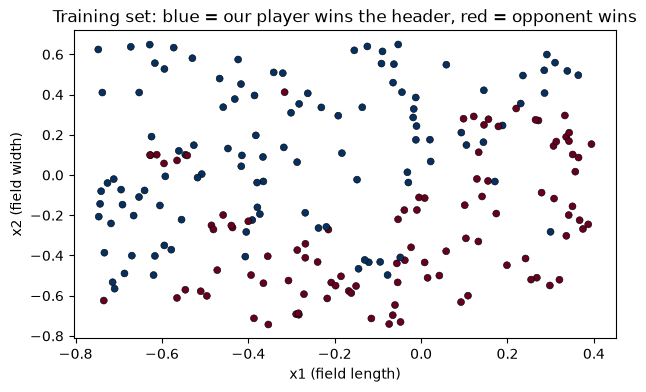

train_X shape: (2, 211)   (features, examples)
train_Y shape: (1, 211)
test_X shape:  (2, 200)
test_Y shape:  (1, 200)


In [6]:
train_X, train_Y, test_X, test_Y = load_2D_dataset()

print("train_X shape:", train_X.shape, "  (features, examples)")
print("train_Y shape:", train_Y.shape)
print("test_X shape: ", test_X.shape)
print("test_Y shape: ", test_Y.shape)

**Look at the plot.** Overall, a diagonal line separates blue (upper-left) from red (lower-right). But the data is **noisy**: a few dots are on the "wrong" side, and there are some **small pockets** of unusual results — a lucky header here, a bad bounce there. These are not real patterns. They will not repeat in future matches.

A good model should learn the **overall diagonal trend** and **ignore the noise**. Keep that in mind for the rest of the lab.

<a name="p2"></a>
## Part 2 — What is overfitting? (read this first)

A neural network with many neurons is very flexible. Given enough training, it can bend its decision boundary around **every single training point**, including the noisy ones. This is called **overfitting**:

| | Training accuracy | Test accuracy | What it means |
|---|---|---|---|
| **Good fit** | high | high, close to training | learned the real pattern |
| **Overfitting (high variance)** | very high | clearly lower | memorised the noise |
| **Underfitting (high bias)** | low | low | too simple to learn the pattern |

**Regularization** = any technique that stops the network from memorising noise, so it **generalizes** better to new data. In this lab you will build two of them:

1. **L2 regularization** — punish large weights, so the network stays smooth and simple.
2. **Dropout** — randomly switch off neurons during training, so no neuron can rely too much on any other.

The network used throughout is the same 3-layer network:

$$\text{input } (2) \;\rightarrow\; \text{LINEAR}\rightarrow\text{ReLU } (20) \;\rightarrow\; \text{LINEAR}\rightarrow\text{ReLU } (3) \;\rightarrow\; \text{LINEAR}\rightarrow\text{sigmoid } (1)$$

<a name="p3"></a>
## Part 3 — Baseline model (no regularization)

The `model()` function below is **already written**. Read it once. Notice the two switches:
- `lambd` — the L2 strength $\lambda$. `lambd = 0` means L2 is **off**. (We write `lambd` because `lambda` is a reserved word in Python.)
- `keep_prob` — the dropout keep probability. `keep_prob = 1` means dropout is **off**.

Depending on these switches, `model()` calls either the baseline functions or the functions **you** will write in Parts 4 and 5.

In [7]:
def model(X, Y, learning_rate=0.3, num_iterations=30000, print_cost=True, lambd=0, keep_prob=1):
    """
    3-layer network: LINEAR -> RELU -> LINEAR -> RELU -> LINEAR -> SIGMOID
    Layer sizes: 2 inputs -> 20 neurons -> 3 neurons -> 1 output.

    lambd     -- L2 strength λ. 0 means "no L2".
    keep_prob -- dropout keep probability. 1 means "no dropout".
    Returns the trained parameters.
    """
    costs = []
    layers_dims = [X.shape[0], 20, 3, 1]
    parameters = initialize_parameters(layers_dims)
    np.random.seed(1)        # makes dropout masks reproducible (set ONCE, before training)

    for i in range(num_iterations):
        # 1) forward pass
        if keep_prob == 1:
            a3, cache = forward_propagation(X, parameters)
        else:
            a3, cache = forward_propagation_with_dropout(X, parameters, keep_prob)

        # 2) cost
        if lambd == 0:
            cost = compute_cost(a3, Y)
        else:
            cost = compute_cost_with_regularization(a3, Y, parameters, lambd)

        # 3) backward pass  (in this lab we use ONE technique at a time)
        assert lambd == 0 or keep_prob == 1, "Use either L2 or dropout, not both, in this lab."
        if lambd == 0 and keep_prob == 1:
            grads = backward_propagation(X, Y, cache)
        elif lambd != 0:
            grads = backward_propagation_with_regularization(X, Y, cache, lambd)
        else:
            grads = backward_propagation_with_dropout(X, Y, cache, keep_prob)

        # 4) gradient-descent update
        parameters = update_parameters(parameters, grads, learning_rate)

        if print_cost and i % 10000 == 0:
            print("Cost after iteration {}: {:.4f}".format(i, cost))
        if i % 1000 == 0:
            costs.append(cost)

    if print_cost:
        plt.plot(costs); plt.ylabel("cost"); plt.xlabel("iterations (x1,000)")
        plt.title("Learning rate = " + str(learning_rate)); plt.show()
    return parameters

Now train the baseline (both switches off). This takes a few seconds.

Cost after iteration 0: 0.6607
Cost after iteration 10000: 0.1996
Cost after iteration 20000: 0.1441


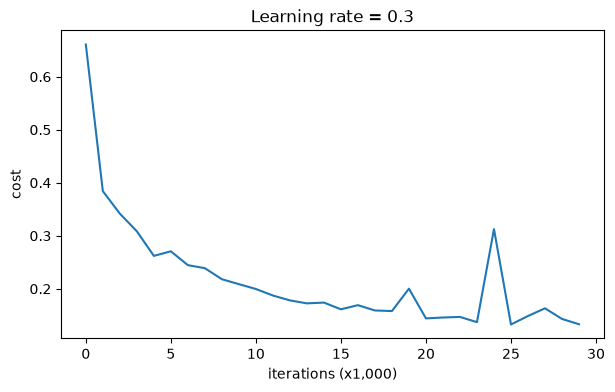

On the training set:
   Accuracy: 93.4%
On the test set:
   Accuracy: 92.0%


In [8]:
parameters = model(train_X, train_Y)
print("On the training set:")
baseline_train = predict(train_X, train_Y, parameters)
print("On the test set:")
baseline_test = predict(test_X, test_Y, parameters)

**Expected output (approximately):** training accuracy ≈ **92.4%**, test accuracy ≈ **92.0%**. This is our **baseline**.

Now look at the decision boundary — the shaded background shows what the model predicts at every point of the field.

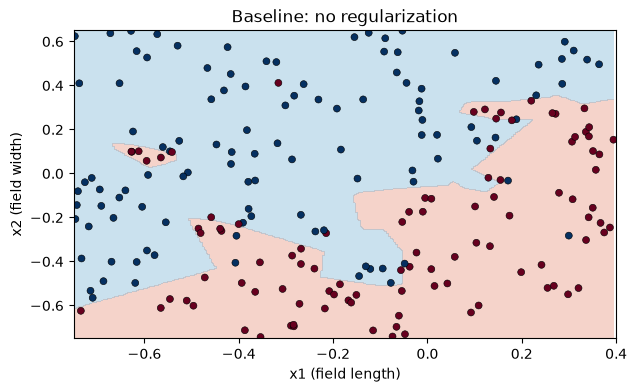

In [9]:
plot_decision_boundary(lambda x: predict_dec(parameters, x.T), train_X, train_Y,
                       title="Baseline: no regularization")

**What do you see?** The boundary is wiggly. It bends to reach into the small noisy pockets so it can classify those few training points "correctly". The model is **overfitting**: it scores higher on training data than on test data, because it memorised noise that does not exist in the test set.

> ✍️ **Question 1.** In one or two sentences: which parts of the decision boundary show overfitting, and why will they hurt on new matches?
>
> *Your answer:* The overfitting is shown where the decision boundary also bends around the noise (the small cluster of dots that are far away in opposite sides).

<a name="p4"></a>
## Part 4 — L2 regularization

### 4.1 The idea in three steps
1. **Large weights → wiggly boundary.** A network with very large weights can change its output sharply for a tiny change in input. That is exactly what lets it carve out small islands around noise.
2. **So we charge a "price" for large weights.** We add a penalty to the cost: the sum of all squared weights.
3. **Gradient descent now has two goals:** fit the data *and* keep the weights small. The result is a smoother, simpler boundary.

### 4.2 The formula
The normal (cross-entropy) cost is:
$$J = -\frac{1}{m} \sum_{i=1}^{m} \Big( y^{(i)}\log a^{[3](i)} + (1-y^{(i)})\log\big(1-a^{[3](i)}\big) \Big) \tag{1}$$

The **regularized** cost adds one term:
$$J_{\text{regularized}} = \underbrace{J}_{\text{cross-entropy}} \;+\; \underbrace{\frac{\lambda}{2m}\Big( \sum W^{[1]2} + \sum W^{[2]2} + \sum W^{[3]2} \Big)}_{\text{L2 penalty}} \tag{2}$$

where $\sum W^{[l]2}$ means "square every entry of $W^{[l]}$, then add them all up". In NumPy: `np.sum(np.square(Wl))`.

**Notes:**
- Only the **weights** $W$ are penalised, not the biases $b$.
- $\lambda$ controls the trade-off. $\lambda = 0$ gives back the normal cost; a very large $\lambda$ forces weights near zero (underfitting).

### Exercise 1 — `compute_cost_with_regularization`
Compute the L2 penalty from equation (2) and add it to the cross-entropy cost.

**Steps:**
1. Compute `np.sum(np.square(W1))`, and the same for `W2` and `W3`.
2. Add the three numbers.
3. Multiply by $\frac{\lambda}{2m}$, i.e. `lambd / (2 * m)`.

In [10]:
# EXERCISE 1: compute_cost_with_regularization

def compute_cost_with_regularization(A3, Y, parameters, lambd):
    """
    Cost with L2 regularization (equation 2).

    Arguments:
    A3 -- output of forward propagation, shape (1, m)
    Y -- true labels, shape (1, m)
    parameters -- dictionary with W1, b1, W2, b2, W3, b3
    lambd -- regularization strength λ (a number)

    Returns:
    cost -- cross-entropy cost + L2 penalty
    """
    m = Y.shape[1]
    W1 = parameters["W1"]
    W2 = parameters["W2"]
    W3 = parameters["W3"]

    cross_entropy_cost = compute_cost(A3, Y)   # part 1: the normal cost (already done for you)

    # part 2: the L2 penalty  =  (λ / (2m)) * (sum of W1²  +  sum of W2²  +  sum of W3²)
    # (≈ 1 line of code)
    # YOUR CODE STARTS HERE
    L2_regularization_cost =  (lambd / (2 * m)) * (np.sum(np.square(W1)) + np.sum(np.square(W2)) + np.sum(np.square(W3)))  # replace None
    # YOUR CODE ENDS HERE

    cost = cross_entropy_cost + L2_regularization_cost
    return cost

In [11]:
test_compute_cost_with_regularization(compute_cost_with_regularization)

✅ cost (lambd = 0.1) is correct
✅ cost (lambd = 0, must equal plain cross-entropy) is correct
All tests passed 🎉


### 4.3 Updating backpropagation
We changed the cost, so the gradients must change too. Only the weight gradients get a new term. Taking the derivative of the penalty:

$$\frac{\partial}{\partial W^{[l]}}\left(\frac{\lambda}{2m}\, \sum W^{[l]2}\right) = \frac{\lambda}{m}\, W^{[l]}$$

So for each layer:
$$dW^{[l]} = \underbrace{\frac{1}{m}\, dZ^{[l]} A^{[l-1]T}}_{\text{normal gradient}} + \frac{\lambda}{m}\, W^{[l]}$$

- $db^{[l]}$ does **not** change (biases are not penalised).
- This is why L2 is also called **weight decay**: in each update $W \leftarrow W - \alpha\, dW$, the extra term $\frac{\lambda}{m} W$ shrinks every weight a little towards zero.

### Exercise 2 — `backward_propagation_with_regularization`
Replace each `None` with the L2 term $\frac{\lambda}{m}W^{[l]}$ for the matching layer (`dW3` uses `W3`, `dW2` uses `W2`, `dW1` uses `W1`).

In [12]:
# EXERCISE 2: backward_propagation_with_regularization

def backward_propagation_with_regularization(X, Y, cache, lambd):
    """
    Backward pass of the baseline model + the L2 term.

    Arguments:
    X -- input data, shape (2, m)
    Y -- true labels, shape (1, m)
    cache -- output of forward_propagation()
    lambd -- regularization strength λ

    Returns:
    gradients -- dictionary of gradients
    """
    m = X.shape[1]
    (Z1, A1, W1, b1, Z2, A2, W2, b2, Z3, A3, W3, b3) = cache

    # ---- layer 3 ----
    dZ3 = A3 - Y
    # (≈ 1 line)  normal gradient  +  (λ / m) * W3
    # YOUR CODE STARTS HERE
    dW3 = 1. / m * np.dot(dZ3, A2.T) + (lambd / m) * W3   # replace None
    # YOUR CODE ENDS HERE
    db3 = 1. / m * np.sum(dZ3, axis=1, keepdims=True)

    # ---- layer 2 ----
    dA2 = np.dot(W3.T, dZ3)
    dZ2 = np.multiply(dA2, np.int64(A2 > 0))
    # (≈ 1 line)
    # YOUR CODE STARTS HERE
    dW2 = 1. / m * np.dot(dZ2, A1.T) + (lambd / m) * W2   # replace None
    # YOUR CODE ENDS HERE
    db2 = 1. / m * np.sum(dZ2, axis=1, keepdims=True)

    # ---- layer 1 ----
    dA1 = np.dot(W2.T, dZ2)
    dZ1 = np.multiply(dA1, np.int64(A1 > 0))
    # (≈ 1 line)
    # YOUR CODE STARTS HERE
    dW1 = 1. / m * np.dot(dZ1, X.T) + (lambd / m) * W1   # replace None
    # YOUR CODE ENDS HERE
    db1 = 1. / m * np.sum(dZ1, axis=1, keepdims=True)

    gradients = {"dZ3": dZ3, "dW3": dW3, "db3": db3, "dA2": dA2,
                 "dZ2": dZ2, "dW2": dW2, "db2": db2, "dA1": dA1,
                 "dZ1": dZ1, "dW1": dW1, "db1": db1}
    return gradients

In [13]:
test_backward_propagation_with_regularization(backward_propagation_with_regularization)

✅ dW1 is correct
✅ dW2 is correct
✅ dW3 is correct
✅ db1 (should NOT change with L2) is correct
All tests passed 🎉


### 4.4 Train with L2 regularization ($\lambda = 0.7$)
Because `lambd` is not 0, `model()` now calls **your** two functions instead of the baseline ones.

Cost after iteration 0: 0.7024
Cost after iteration 10000: 0.4121
Cost after iteration 20000: 0.4092


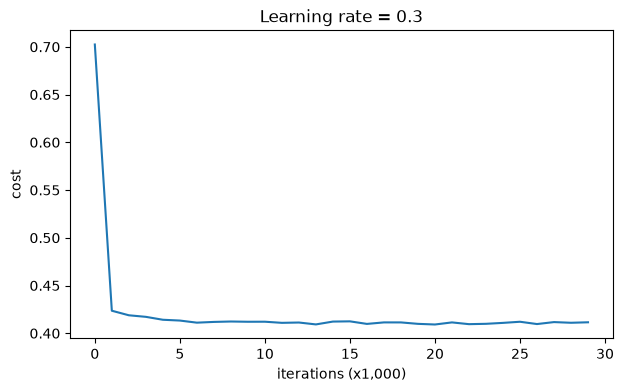

On the training set:
   Accuracy: 84.8%
On the test set:
   Accuracy: 95.0%


In [14]:
parameters = model(train_X, train_Y, lambd=0.7)
print("On the training set:")
l2_train = predict(train_X, train_Y, parameters)
print("On the test set:")
l2_test = predict(test_X, test_Y, parameters)

**Expected output (approximately):** training ≈ **84.8%**, test ≈ **95.0%**.

Training accuracy went **down** and test accuracy went **up**. That is not a bug — the model has stopped "scoring points" on the noisy training examples, and it now generalizes better.

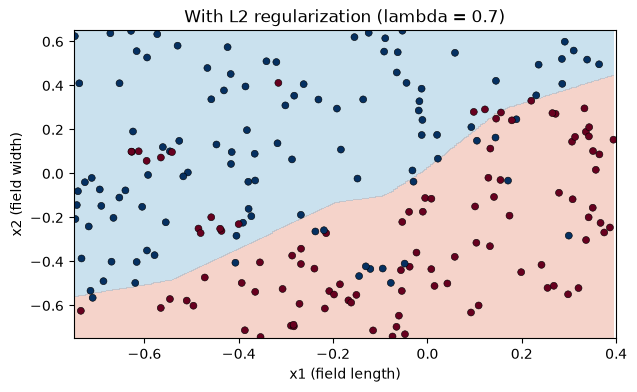

In [15]:
plot_decision_boundary(lambda x: predict_dec(parameters, x.T), train_X, train_Y,
                       title="With L2 regularization (lambda = 0.7)")

<div style="background:#eaf4fb;border-left:6px solid #2e86c1;padding:10px 16px">

**Remember — L2 regularization**
- **Cost:** add $\frac{\lambda}{2m}\sum\|W\|^2$.
- **Backprop:** add $\frac{\lambda}{m}W^{[l]}$ to each $dW^{[l]}$; $db$ is unchanged.
- **Effect:** weights become smaller ("weight decay") → smoother decision boundary.
- $\lambda$ is a **hyperparameter**: tune it on a validation (dev) set. Too large → over-smoothed boundary (high bias).
</div>

<a name="p5"></a>
## Part 5 — Dropout

### 5.1 The idea
At **every training iteration**, each neuron in a hidden layer is randomly **switched off** (set to 0) with probability $1 - \texttt{keep\_prob}$.

- A switched-off neuron contributes nothing in the forward pass **and** receives no gradient in the backward pass of that iteration.
- The next iteration picks a **new random set** of neurons to switch off.

**Why does this help?** Each iteration effectively trains a different, smaller network. A neuron can never be sure that a specific neighbour will be present, so it cannot rely on one fragile combination of features to memorise a noisy point. It must learn robust features that are useful on their own. The final network behaves like an average of many smaller networks, which generalizes better.

Run the cell below to see two training iterations of the same network with `keep_prob = 0.5`. Grey neurons with a red ✕ are switched off in that iteration; notice the mask changes every time.

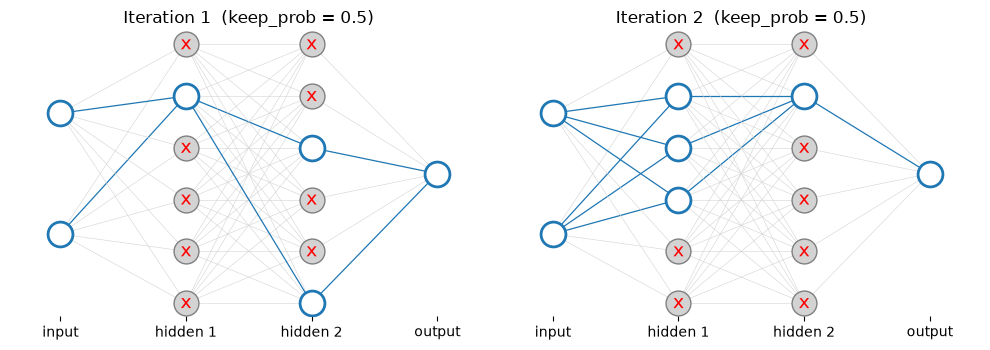

In [16]:
draw_dropout_example(keep_prob=0.5)

### 5.2 Inverted dropout, step by step
We apply dropout to hidden layers 1 and 2 only (never to the input or the output layer). For layer 1, with `A1` of shape $(20, m)$:

| Step | What to do | NumPy |
|---|---|---|
| 1 | Make a random matrix `D1` with the **same shape as `A1`**, values in $[0, 1)$ | `np.random.rand(A1.shape[0], A1.shape[1])` |
| 2 | Turn `D1` into a **mask** of 1s (keep) and 0s (drop) | `(D1 < keep_prob).astype(int)` |
| 3 | **Switch off** the dropped neurons | `A1 = A1 * D1` |
| 4 | **Scale up** the survivors | `A1 = A1 / keep_prob` |

**Why Step 2 works:** a number drawn uniformly from $[0, 1)$ is below `keep_prob` with probability exactly `keep_prob`. With `keep_prob = 0.8`, about 80% of the entries become 1 and 20% become 0.

**Why Step 4 (dividing by `keep_prob`)?** If we keep only 80% of the neurons, the next layer receives on average only 80% of the usual signal. Dividing by 0.8 brings the **expected value** back to what it was without dropout. This is called **inverted dropout**, and it is the reason we do **not** need to change anything at test time.

### Exercise 3 — `forward_propagation_with_dropout`
Apply the four steps to `A1`, then the same four steps to `A2` (using `D2`).

⚠️ Use exactly `np.random.rand(A1.shape[0], A1.shape[1])` for Step 1 (and the same pattern for `A2`), so your random numbers match the test.

In [17]:
# EXERCISE 3: forward_propagation_with_dropout

def forward_propagation_with_dropout(X, parameters, keep_prob=0.5):
    """
    LINEAR -> RELU + DROPOUT -> LINEAR -> RELU + DROPOUT -> LINEAR -> SIGMOID

    Arguments:
    X -- input data, shape (2, m)
    parameters -- W1 (20,2), b1 (20,1), W2 (3,20), b2 (3,1), W3 (1,3), b3 (1,1)
    keep_prob -- probability of KEEPING each hidden neuron

    Returns:
    A3 -- output, shape (1, m)
    cache -- everything backprop needs (including the masks D1 and D2)
    """
    W1, b1 = parameters["W1"], parameters["b1"]
    W2, b2 = parameters["W2"], parameters["b2"]
    W3, b3 = parameters["W3"], parameters["b3"]

    # ---- hidden layer 1 ----
    Z1 = np.dot(W1, X) + b1
    A1 = relu(Z1)
    # (≈ 4 lines)
    # YOUR CODE STARTS HERE
    D1 = np.random.rand(A1.shape[0], A1.shape[1])   # Step 1: random numbers in [0,1), same shape as A1  ->  np.random.rand(A1.shape[0], A1.shape[1])
    D1 = (D1 < keep_prob).astype(int)    # Step 2: turn them into a 0/1 mask using keep_prob  ->  (D1 < keep_prob).astype(int)
    A1 = A1 * D1   # Step 3: switch off the dropped neurons             ->  multiply A1 by D1
    A1 = A1 / keep_prob   # Step 4: scale up the survivors                     ->  divide A1 by keep_prob
    # YOUR CODE ENDS HERE

    # ---- hidden layer 2 ----
    Z2 = np.dot(W2, A1) + b2
    A2 = relu(Z2)
    # (≈ 4 lines) — same 4 steps, now for A2
    # YOUR CODE STARTS HERE
    D2 =  np.random.rand(A2.shape[0], A2.shape[1])   # Step 1
    D2 = (D2 < keep_prob).astype(int)   # Step 2
    A2 = A2 * D2   # Step 3
    A2 = A2 / keep_prob   # Step 4
    # YOUR CODE ENDS HERE

    # ---- output layer (no dropout here) ----
    Z3 = np.dot(W3, A2) + b3
    A3 = sigmoid(Z3)

    cache = (Z1, D1, A1, W1, b1, Z2, D2, A2, W2, b2, Z3, A3, W3, b3)
    return A3, cache

In [18]:
test_forward_propagation_with_dropout(forward_propagation_with_dropout)

✅ A3 is correct
✅ D1 (mask of layer 1) is correct
✅ D2 (mask of layer 2) is correct
All tests passed 🎉


### 5.3 Backward propagation with dropout
The backward pass must "see" the **same** network as the forward pass. So for each hidden layer:

1. **Apply the same mask** stored in the cache: `dA1 = dA1 * D1`. A neuron that was switched off in the forward pass gets zero gradient.
2. **Apply the same scaling**: `dA1 = dA1 / keep_prob`. In the forward pass we computed $A^{[1]}_{\text{new}} = A^{[1]} \cdot D^{[1]} / \texttt{keep\_prob}$; the derivative of that operation multiplies by the same $D^{[1]} / \texttt{keep\_prob}$.

Do the same for `dA2` with `D2`.

### Exercise 4 — `backward_propagation_with_dropout`

In [19]:
# EXERCISE 4: backward_propagation_with_dropout

def backward_propagation_with_dropout(X, Y, cache, keep_prob):
    """
    Backward pass of the model that used dropout in hidden layers 1 and 2.

    Arguments:
    X -- input data, shape (2, m)
    Y -- true labels, shape (1, m)
    cache -- output of forward_propagation_with_dropout()
    keep_prob -- the same keep_prob used in the forward pass

    Returns:
    gradients -- dictionary of gradients
    """
    m = X.shape[1]
    (Z1, D1, A1, W1, b1, Z2, D2, A2, W2, b2, Z3, A3, W3, b3) = cache

    # ---- layer 3 ----
    dZ3 = A3 - Y
    dW3 = 1. / m * np.dot(dZ3, A2.T)
    db3 = 1. / m * np.sum(dZ3, axis=1, keepdims=True)

    # ---- layer 2 ----
    dA2 = np.dot(W3.T, dZ3)
    # (≈ 2 lines)
    # YOUR CODE STARTS HERE
    dA2 = dA2 * D2   # Step 1: apply the SAME mask D2 used in the forward pass
    dA2 = dA2 / keep_prob   # Step 2: divide by keep_prob (same scaling as the forward pass)
    # YOUR CODE ENDS HERE
    dZ2 = np.multiply(dA2, np.int64(A2 > 0))
    dW2 = 1. / m * np.dot(dZ2, A1.T)
    db2 = 1. / m * np.sum(dZ2, axis=1, keepdims=True)

    # ---- layer 1 ----
    dA1 = np.dot(W2.T, dZ2)
    # (≈ 2 lines)
    # YOUR CODE STARTS HERE
    dA1 = dA1 * D1   # Step 1: apply mask D1
    dA1 = dA1 / keep_prob  # Step 2: divide by keep_prob
    # YOUR CODE ENDS HERE
    dZ1 = np.multiply(dA1, np.int64(A1 > 0))
    dW1 = 1. / m * np.dot(dZ1, X.T)
    db1 = 1. / m * np.sum(dZ1, axis=1, keepdims=True)

    gradients = {"dZ3": dZ3, "dW3": dW3, "db3": db3, "dA2": dA2,
                 "dZ2": dZ2, "dW2": dW2, "db2": db2, "dA1": dA1,
                 "dZ1": dZ1, "dW1": dW1, "db1": db1}
    return gradients

In [20]:
test_backward_propagation_with_dropout(backward_propagation_with_dropout)

✅ dA1 is correct
✅ dA2 is correct
✅ dW1 is correct
All tests passed 🎉


### 5.4 Train with dropout (`keep_prob = 0.7`)
Each hidden neuron in layers 1 and 2 is now switched off with probability 30% at every iteration. `model()` calls **your** dropout functions.

Cost after iteration 0: 0.6643
Cost after iteration 10000: 0.3635
Cost after iteration 20000: 0.3685


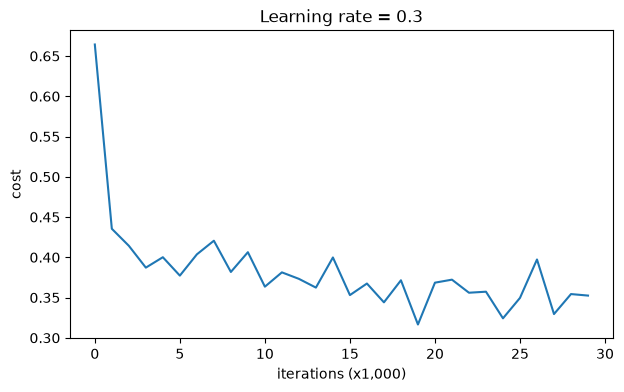

On the training set:
   Accuracy: 88.2%
On the test set:
   Accuracy: 94.0%


In [21]:
parameters = model(train_X, train_Y, keep_prob=0.7, learning_rate=0.3)
print("On the training set:")
dropout_train = predict(train_X, train_Y, parameters)
print("On the test set:")
dropout_test = predict(test_X, test_Y, parameters)

**Expected output (approximately):** training ≈ **88.2%**, test ≈ **94.0%**.

Note that `predict()` uses the normal `forward_propagation` — **no dropout at test time**.

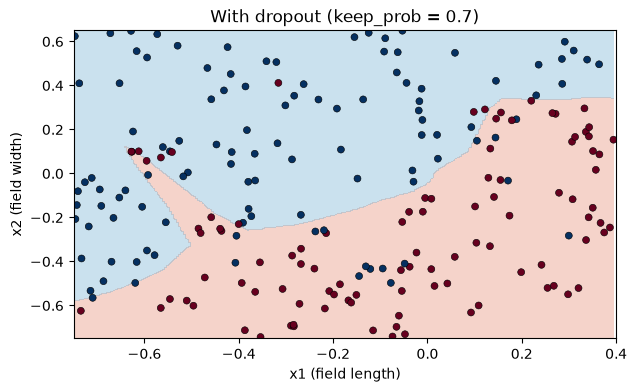

In [22]:
plot_decision_boundary(lambda x: predict_dec(parameters, x.T), train_X, train_Y,
                       title="With dropout (keep_prob = 0.7)")

<div style="background:#eaf4fb;border-left:6px solid #2e86c1;padding:10px 16px">

**Remember — Dropout**
- Use dropout **only during training**. Never drop neurons when making predictions.
- Apply it in **both** the forward pass (mask + scale) and the backward pass (same mask + same scale).
- Divide by `keep_prob` (inverted dropout) so the expected activations stay the same.
- `keep_prob` is a hyperparameter. Lower `keep_prob` = stronger regularization.
- Frameworks provide it ready-made, e.g. `tf.keras.layers.Dropout(rate=0.3)` or `torch.nn.Dropout(p=0.3)`. Careful: there `rate`/`p` is the probability of **dropping**, i.e. $1 - \texttt{keep\_prob}$.
</div>

<a name="p6"></a>
## Part 6 — Experiment: choosing λ

$\lambda$ is a hyperparameter: there is no formula for the best value, you must try several. Run the cell below. It trains one L2 model per value of $\lambda$ (this takes about a minute) and prints a small table.

In [23]:
lambdas = [0, 0.3, 0.7, 3.0, 30.0]
print("{:>8} | {:>10} | {:>9}".format("lambda", "train acc", "test acc"))
print("-" * 33)
sweep = {}
for lam in lambdas:
    p = model(train_X, train_Y, lambd=lam, print_cost=False)
    A_tr, _ = forward_propagation(train_X, p); A_te, _ = forward_propagation(test_X, p)
    tr = np.mean((A_tr > 0.5) == train_Y); te = np.mean((A_te > 0.5) == test_Y)
    sweep[lam] = (tr, te)
    print("{:>8} | {:>9.1f}% | {:>8.1f}%".format(lam, 100 * tr, 100 * te))

  lambda |  train acc |  test acc
---------------------------------


       0 |      93.4% |     92.0%
     0.3 |      83.4% |     93.0%
     0.7 |      84.8% |     95.0%
     3.0 |      84.4% |     96.0%
    30.0 |      52.1% |     59.5%


> ✍️ **Question 2.** Using your table: what happens to **training** accuracy as $\lambda$ grows? What happens to **test** accuracy? Which $\lambda$ would you choose, and why?
>
> *Your answer:* As lambda increases, the traning accuracy decreases but the testing accuracy increases (the accuracy may drop when $\lambda$ becomes very large). I would choose 0.7 as my $\lambda$ as it gives a high testing accuracy without there being less difference in the traning accuracy.

> ✍️ **Question 3.** For the largest $\lambda$, is the model overfitting or underfitting? How can you tell from the numbers?
>
> *Your answer:* Model is underfitting as both the training and testing accuracy are low (maybe because the regularization is too strong)

> ✍️ **Question 4 (important).** In this lab we chose $\lambda$ by looking at the **test** set. Why is that bad practice in a real project, and what should we use instead?
>
> *Your answer:* Using the test set to choose λ is bad because the model is then tuned to the test data, making the test accuracy look better than it really is. We should use a validation set instead.

<a name="p7"></a>
## Part 7 — Results and conclusions
Run the cell to print a summary of your three models.

In [24]:
print("{:<36} | {:>10} | {:>9}".format("Model", "train acc", "test acc"))
print("-" * 62)
for name, tr, te in [("3-layer NN, no regularization", baseline_train, baseline_test),
                     ("3-layer NN, L2 (lambda = 0.7)", l2_train, l2_test),
                     ("3-layer NN, dropout (keep_prob = 0.7)", dropout_train, dropout_test)]:
    print("{:<36} | {:>9.1f}% | {:>8.1f}%".format(name, 100 * tr, 100 * te))

Model                                |  train acc |  test acc
--------------------------------------------------------------
3-layer NN, no regularization        |      93.4% |     92.0%
3-layer NN, L2 (lambda = 0.7)        |      84.8% |     95.0%
3-layer NN, dropout (keep_prob = 0.7) |      88.2% |     94.0%


**Key observation:** regularization **lowers training accuracy** but **raises test accuracy**. It deliberately stops the network from memorising the training set, and that is exactly what makes it better on new data. Remember: the test score is the one that matters.

> ✍️ **Question 5.** Why is the training accuracy of the regularized models lower than the baseline, even though they are "better" models?
>
> *Your answer:* Regularization stops the model from memorizing the training data, so it makes more mistakes on training examples but generalizes better to new data.

> ✍️ **Question 6.** A classmate applies dropout inside `predict()` as well, "to be consistent with training". What will happen to the predictions, and why is this wrong?
>
> *Your answer:* Dropout should be turned off during prediction as using it makes predictions random and less accurate because some neurons are randomly ignored.

> ✍️ **Question 7.** Explain in your own words why we divide by `keep_prob` in inverted dropout. What would go wrong at test time if we forgot?
>
> *Your answer:* We divide by keep_prob during training to keep the expected activation level the same when neurons are dropped. If we forget, test-time activations would be too large and predictions would be wrong.

<div style="background:#eafaf1;border-left:6px solid #27ae60;padding:10px 16px">

**What to take away from Lab 4**
1. Overfitting = high training accuracy, lower test accuracy. Regularization fights it.
2. **L2 regularization** adds $\frac{\lambda}{2m}\sum\|W\|^2$ to the cost and $\frac{\lambda}{m}W$ to each $dW$. It shrinks weights and smooths the boundary.
3. **Dropout** randomly switches off hidden neurons during training (forward *and* backward), with inverted scaling by `keep_prob`. Never use it at test time.
4. $\lambda$ and `keep_prob` are hyperparameters: tune them on a validation set, not the test set.
</div>

**Before submitting:** `Kernel → Restart & Run All`, check that every test shows ✅, and that all ✍️ questions are answered.